# Background Removal Pipeline — Model 1
### Ensemble Segmentation: BiRefNet + rembg (IS-Net)
### Target: Egyptian Monuments / Landmarks (foreground) — NOT people

| Component | Model | Purpose |
|-----------|-------|---------|
| Primary Segmentation | **BiRefNet** (zhengpeng7) | Fine edges, complex boundaries |
| Secondary Segmentation | **rembg / IS-Net** | General-purpose baseline |
| Post-Processing | **Guided Filter + Morphology** | Edge-preserving mask refinement |
| Subject Selection | **LargeStructureSelector** | Keep largest structure, suppress small objects |

**Environment:** Anaconda — JupyterLab / Jupyter Notebook (local machine)  
**Output directory:** `C:\Ahmed Nasser\Artificial Intelligence\Graduation Project\CNN\Remove Background\Model 1`

> **VRAM Fix (v5.1) — changes from v5.0:**
> - SAM2 fully removed: it consumed VRAM on load even when its weight was 0.0.
> - BiRefNet forced to CPU via `CONFIG.BIREFNET_DEVICE` to prevent CUDA OOM on large datasets.
> - `torch.cuda.empty_cache()` + `gc.collect()` called after every engine inference and after every image.

In [1]:
import sys
import os
import logging
import warnings

warnings.filterwarnings("ignore")

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s  [%(levelname)s]  %(message)s",
    datefmt="%H:%M:%S",
)
log = logging.getLogger("bgremoval")


class PipelineConfig:
    """
    Central configuration for the background removal pipeline.

    Edit values here to change pipeline behavior globally.
    No other cell should contain hard-coded paths or numeric constants.

    VRAM Fix (v5.1):
      - SAM2 has been fully disabled. It was loading into VRAM even when
        W_SAM2 was 0.0, causing CUDA out-of-memory errors.
      - BiRefNet now runs on CPU (BIREFNET_DEVICE = "cpu") by default.
        Set to "cuda" only if your GPU has at least 8 GB of free VRAM
        after rembg is loaded.
      - CUDA cache is explicitly flushed after every inference call and
        after every image to prevent memory accumulation.
    """

    # ------------------------------------------------------------------
    # Paths
    # ------------------------------------------------------------------
    INPUT_DIR: str = (
        r"C:\Ahmed Nasser\Artificial Intelligence"
        r"\Graduation Project\CNN\Data Back"
    )
    OUTPUT_DIR: str = (
        r"C:\Ahmed Nasser\Artificial Intelligence"
        r"\Graduation Project\CNN\Remove Background\Model 1"
    )

    # ------------------------------------------------------------------
    # Ensemble weights  (SAM2 removed; BiRefNet + rembg only)
    # ------------------------------------------------------------------
    W_BIREFNET: float = 0.60
    W_REMBG:    float = 0.40

    # ------------------------------------------------------------------
    # BiRefNet
    # BIREFNET_DEVICE is intentionally separate from the main device.
    # Running BiRefNet on CPU keeps the GPU free for rembg and prevents
    # the CUDA OOM errors observed during bulk dataset processing.
    # ------------------------------------------------------------------
    BIREFNET_MODEL_ID: str     = "ZhengPeng7/BiRefNet"
    BIREFNET_INPUT_SIZE: tuple = (1024, 1024)
    BIREFNET_MEAN: list        = [0.485, 0.456, 0.406]
    BIREFNET_STD: list         = [0.229, 0.224, 0.225]
    BIREFNET_DEVICE: str       = "cpu"   # forced CPU — change to "cuda" only with 8+ GB free VRAM

    # ------------------------------------------------------------------
    # Mask refinement
    # ------------------------------------------------------------------
    MORPH_OPEN_KERNEL: int     = 3
    MORPH_CLOSE_KERNEL: int    = 7
    GF_RADIUS: int             = 10
    GF_EPS: float              = 1e-4
    BILATERAL_D: int           = 9
    BILATERAL_SIGMA_C: int     = 80
    BILATERAL_SIGMA_S: int     = 80
    MIN_COMPONENT_RATIO: float = 0.001

    # ------------------------------------------------------------------
    # Subject selector
    # Components below this fraction of total image area are discarded.
    # This removes tourists and people while keeping large monuments.
    # ------------------------------------------------------------------
    MIN_SUBJECT_RATIO: float = 0.05

    # ------------------------------------------------------------------
    # Empty-mask guard
    # Images whose foreground ratio falls below this threshold are skipped.
    # ------------------------------------------------------------------
    MIN_FOREGROUND_RATIO: float = 0.01

    # ------------------------------------------------------------------
    # Output
    # ------------------------------------------------------------------
    COMPARISON_DPI: int = 150
    SUPPORTED_EXT: set  = {".jpg", ".jpeg", ".png", ".bmp", ".tiff", ".webp"}

    # ------------------------------------------------------------------
    # Hardware (auto-detected below)
    # ------------------------------------------------------------------
    device: str          = "cpu"
    gpu_name: str        = None
    gpu_memory_gb: float = None

    def __init__(self):
        self._detect_hardware()

    def _detect_hardware(self) -> None:
        """Detect GPU and set self.device accordingly."""
        try:
            import torch
            if torch.cuda.is_available():
                self.device        = "cuda"
                self.gpu_name      = torch.cuda.get_device_name(0)
                self.gpu_memory_gb = round(
                    torch.cuda.get_device_properties(0).total_memory / (1024 ** 3), 2
                )
                log.info("GPU          : %s", self.gpu_name)
                log.info("GPU Memory   : %.2f GB", self.gpu_memory_gb)
                log.info("CUDA Version : %s", torch.version.cuda)
            else:
                log.info("GPU not available — running on CPU.")
        except ImportError:
            log.warning("PyTorch not installed. Run Cell 2 first.")
        log.info("Active device    : %s", self.device.upper())
        log.info("BiRefNet device  : %s (forced — see BIREFNET_DEVICE)", self.BIREFNET_DEVICE.upper())


CONFIG = PipelineConfig()

02:13:38  [INFO]  GPU          : NVIDIA GeForce RTX 5060 Laptop GPU
02:13:38  [INFO]  GPU Memory   : 7.96 GB
02:13:38  [INFO]  CUDA Version : 12.8
02:13:38  [INFO]  Active device    : CUDA
02:13:38  [INFO]  BiRefNet device  : CPU (forced — see BIREFNET_DEVICE)


## Cell 2 — Install Dependencies

Run this cell once. Restart the kernel after the first install, then run all cells from the top.

| Package | Purpose |
|---------|---------|
| `torch`, `torchvision` | Deep learning backend |
| `Pillow`, `opencv-python` | Image I/O and processing |
| `transformers`, `timm` | BiRefNet via Hugging Face |
| `scikit-image`, `scipy` | Morphological tools |
| `rembg` | IS-Net background removal |
| `tqdm`, `matplotlib` | Progress display and visualization |

> SAM2 is no longer installed — it has been removed from the pipeline entirely.

In [2]:
import subprocess, sys

# SAM2 has been removed from this package list.
# It consumed GPU memory on load even when its ensemble weight was 0.0.
PACKAGES = [
    # "torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118",
    "Pillow>=10.0.0",
    "opencv-python",
    "transformers>=4.40.0 timm",
    "scikit-image scipy",
    "tqdm matplotlib ipywidgets",
    "rembg[gpu]" if CONFIG.device == "cuda" else "rembg",
]

for pkg in PACKAGES:
    short = pkg[:72] + "..." if len(pkg) > 72 else pkg
    log.info("Installing: %s", short)
    res = subprocess.run(
        f"pip install -q {pkg}",
        shell=True, capture_output=True, text=True,
    )
    if res.returncode != 0:
        log.warning("Warning during install (may already exist): %s", short)
    else:
        log.info("Done: %s", short)

log.info("All packages ready. Restart kernel if this was the first run.")

02:13:38  [INFO]  Installing: Pillow>=10.0.0
02:13:39  [INFO]  Done: Pillow>=10.0.0
02:13:39  [INFO]  Installing: opencv-python
02:13:41  [INFO]  Done: opencv-python
02:13:41  [INFO]  Installing: transformers>=4.40.0 timm
02:13:42  [INFO]  Done: transformers>=4.40.0 timm
02:13:42  [INFO]  Installing: scikit-image scipy
02:13:43  [INFO]  Done: scikit-image scipy
02:13:43  [INFO]  Installing: tqdm matplotlib ipywidgets
02:13:45  [INFO]  Done: tqdm matplotlib ipywidgets
02:13:45  [INFO]  Installing: rembg[gpu]
02:13:46  [INFO]  Done: rembg[gpu]
02:13:46  [INFO]  All packages ready. Restart kernel if this was the first run.


## Cell 3 — Imports

Any import failure here means a package is missing — re-run Cell 2 to fix it.

In [3]:
import torch
import numpy as np
import cv2
from PIL import Image
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt
from datetime import datetime
import gc
import json
import time

log.info("All imports successful.")

02:13:47  [INFO]  All imports successful.


## Cell 4 — Image Data Loader

Recursively scans `CONFIG.INPUT_DIR` for every supported image format.  
Yields `(Path, PIL.Image in RGBA mode)` tuples to the pipeline.

Supported formats: `.jpg` `.jpeg` `.png` `.bmp` `.tiff` `.webp`

In [4]:
class ImageDataLoader:
    """
    Recursively discovers all supported images under CONFIG.INPUT_DIR.
    Yields (Path, PIL.Image in RGBA mode) for each discovered file.
    """

    def __init__(self, input_dir: str):
        self.root         = Path(input_dir)
        self.image_paths: list[Path] = []
        self._discover()

    def _discover(self) -> None:
        """Walk the directory tree and collect unique image paths."""
        if not self.root.exists():
            log.error("Input directory not found: %s", self.root)
            return

        seen: set[Path] = set()
        for ext in CONFIG.SUPPORTED_EXT:
            for p in list(self.root.rglob(f"*{ext}")) + list(self.root.rglob(f"*{ext.upper()}")):
                resolved = p.resolve()
                if resolved not in seen:
                    seen.add(resolved)
                    self.image_paths.append(p)

        log.info("Images discovered: %d  |  folder: %s", len(self.image_paths), self.root)

    def __len__(self) -> int:
        return len(self.image_paths)

    def __iter__(self):
        for path in self.image_paths:
            try:
                img = Image.open(path)
                yield path, img.convert("RGBA")
            except Exception as exc:
                log.warning("Skipped %s — could not open: %s", path.name, exc)


loader = ImageDataLoader(CONFIG.INPUT_DIR)
print(f"Total images ready for processing: {len(loader)}")

02:13:47  [INFO]  Images discovered: 93  |  folder: C:\Ahmed Nasser\Artificial Intelligence\Graduation Project\CNN\Data Back


Total images ready for processing: 93


## Cell 5 — Large Structure Selector

After the ensemble produces a raw mask, `LargeStructureSelector` scans all connected
foreground components and suppresses any component whose area is below
`CONFIG.MIN_SUBJECT_RATIO` of the total image area.  
This removes tourists, people, and small objects while preserving pyramids,
temples, statues, and other large architectural structures.

| Parameter | Default | Effect |
|-----------|---------|--------|
| `MIN_SUBJECT_RATIO` | 0.05 | Suppress components smaller than 5% of image area |

In [5]:
class LargeStructureSelector:
    """
    Post-processes a binary mask to retain only large dominant structures.

    Connected foreground components whose pixel area falls below
    CONFIG.MIN_SUBJECT_RATIO * total_image_area are zeroed out.

    This ensures that tourists, people, or small objects in front of a
    monument are not preserved as the primary foreground subject.
    """

    def select(
        self,
        mask: np.ndarray,
        img_shape: tuple,
    ) -> np.ndarray:
        """
        Remove small foreground components from mask.

        Parameters
        ----------
        mask      : uint8 H x W mask (0-255)
        img_shape : (height, width) of the source image

        Returns
        -------
        Filtered uint8 mask with small components zeroed.
        """
        h, w        = img_shape[:2]
        total_px    = h * w
        min_area_px = int(total_px * CONFIG.MIN_SUBJECT_RATIO)

        binary = (mask > 127).astype(np.uint8)
        n, labels, stats, _ = cv2.connectedComponentsWithStats(binary)

        # Build output mask: keep only components above the minimum area
        filtered = np.zeros_like(mask)
        kept     = 0
        removed  = 0

        for i in range(1, n):  # label 0 is background
            area = stats[i, cv2.CC_STAT_AREA]
            if area >= min_area_px:
                filtered[labels == i] = mask[labels == i]
                kept += 1
            else:
                removed += 1

        if removed > 0:
            log.info(
                "  LargeStructureSelector: kept %d component(s), removed %d small object(s).",
                kept, removed,
            )

        return filtered


subject_selector = LargeStructureSelector()
log.info("LargeStructureSelector ready. MIN_SUBJECT_RATIO = %.2f", CONFIG.MIN_SUBJECT_RATIO)

02:13:47  [INFO]  LargeStructureSelector ready. MIN_SUBJECT_RATIO = 0.05


## Cell 6 — Segmentation Engines

Two independent models run on every image (SAM2 has been removed entirely).  
Each returns a grayscale alpha mask (0 = background, 255 = foreground).  
If a model fails it returns `None` and its weight is redistributed to the remaining engine.

| Engine | Backbone | Device | Strength |
|--------|----------|--------|----------|
| **BiRefNetEngine** | BiRefNet-General | **CPU** (forced) | Fine textures, carved detail, complex boundaries |
| **RembgEngine** | IS-Net General | CUDA / CPU | Fast and reliable wide-domain baseline |

> **VRAM fix:** BiRefNet loads on CPU. rembg uses CUDA when available.  
> Both engines call `torch.cuda.empty_cache()` immediately after inference.

In [6]:
# ============================================================
# BiRefNet Engine
# ============================================================

class BiRefNetEngine:
    """
    Bilateral Reference Network for dichotomous image segmentation.

    Runs at 1024x1024 internally, then resizes the mask back to the
    original image dimensions using bilinear interpolation.

    VRAM fix: loaded on CONFIG.BIREFNET_DEVICE (default: CPU) to keep
    the GPU free for rembg and prevent CUDA out-of-memory errors when
    processing large datasets image by image.

    Reference: https://huggingface.co/ZhengPeng7/BiRefNet
    """

    def __init__(self):
        # Always use the dedicated BiRefNet device, not the main pipeline device
        self.device    = CONFIG.BIREFNET_DEVICE
        self.model     = None
        self.transform = None
        self._load()

    def _load(self) -> None:
        """Download and initialize BiRefNet from Hugging Face."""
        log.info("Loading BiRefNet on %s...", self.device.upper())
        try:
            from transformers import AutoModelForImageSegmentation
            from torchvision import transforms

            self.model = (
                AutoModelForImageSegmentation
                .from_pretrained(CONFIG.BIREFNET_MODEL_ID, trust_remote_code=True)
                .to(self.device)
                .eval()
            )
            self.transform = transforms.Compose([
                transforms.Resize(CONFIG.BIREFNET_INPUT_SIZE),
                transforms.ToTensor(),
                transforms.Normalize(mean=CONFIG.BIREFNET_MEAN, std=CONFIG.BIREFNET_STD),
            ])
            log.info("BiRefNet loaded successfully on %s.", self.device.upper())
        except Exception as exc:
            log.error("BiRefNet failed to load: %s", exc)
            self.model = None

    def predict(self, pil_image: Image.Image) -> np.ndarray | None:
        """Return a uint8 alpha mask at the original image resolution."""
        if self.model is None:
            return None
        orig_w, orig_h = pil_image.size
        tensor = self.transform(pil_image.convert("RGB")).unsqueeze(0).to(self.device)
        with torch.no_grad():
            preds = self.model(tensor)[-1].sigmoid().cpu()
        mask = (preds[0].squeeze().numpy() * 255).astype(np.uint8)

        # Release tensors immediately to free memory
        del tensor, preds
        gc.collect()

        return cv2.resize(mask, (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)


# ============================================================
# rembg Engine
# ============================================================

class RembgEngine:
    """
    rembg with IS-Net general-use backbone.

    Provides a strong, fast baseline for wide-domain background removal.
    Runs on CUDA when available; falls back to CPU automatically.

    Reference: https://github.com/danielgatis/rembg
    """

    MODEL_NAME = "isnet-general-use"

    def __init__(self):
        self.session   = None
        self.remove_fn = None
        self._load()

    def _load(self) -> None:
        log.info("Loading rembg (IS-Net)...")
        try:
            from rembg import remove, new_session
            self.remove_fn = remove
            self.session   = new_session(self.MODEL_NAME)
            log.info("rembg loaded successfully.")
        except Exception as exc:
            log.error("rembg failed to load: %s", exc)

    def predict(self, pil_image: Image.Image) -> np.ndarray | None:
        """Extract the alpha channel of the rembg result as a uint8 mask."""
        if self.session is None:
            return None
        result = self.remove_fn(pil_image, session=self.session)

        # Flush GPU memory after rembg inference to prevent VRAM accumulation
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        gc.collect()

        arr = np.array(result)
        return arr[:, :, 3] if result.mode == "RGBA" else np.array(result.convert("L"))

## Cell 7 — Mask Refinement and Ensemble Merger

### MaskRefiner — 6-stage post-processing pipeline

| Stage | Operation | Purpose |
|-------|-----------|---------|
| 1 | Morphological Open | Remove isolated noise pixels |
| 2 | Morphological Close | Fill small holes inside the subject |
| 3 | Guided Filter | Edge-preserving smoothing using image luminance |
| 4 | Soft-threshold blend | Smooth uncertain boundary zone (0.3 – 0.7) |
| 5 | Bilateral Filter | Final surface smoothing |
| 6 | Component Filter | Remove floating fragments below area threshold |

### EnsembleMerger — weighted average

```
final = BiRefNet x 0.60  +  rembg x 0.40
```

In [7]:
class MaskRefiner:
    """
    Six-stage edge-preserving mask post-processor.
    All numeric parameters come from CONFIG.
    """

    def __init__(self, device: str = "cpu"):
        self.device = device

    def refine(
        self,
        img_rgb: np.ndarray,
        raw_mask: np.ndarray,
    ) -> np.ndarray:
        """
        Refine a uint8 mask using img_rgb as a structural guide.

        Parameters
        ----------
        img_rgb  : H x W x 3  numpy array (uint8, RGB)
        raw_mask : H x W      numpy array (uint8, 0-255)

        Returns
        -------
        Refined uint8 mask (0-255).
        """
        m = raw_mask.astype(np.uint8)

        # Stage 1: Morphological open — remove noise specks
        k_open = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (CONFIG.MORPH_OPEN_KERNEL, CONFIG.MORPH_OPEN_KERNEL),
        )
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, k_open)

        # Stage 2: Morphological close — fill internal holes
        k_close = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (CONFIG.MORPH_CLOSE_KERNEL, CONFIG.MORPH_CLOSE_KERNEL),
        )
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k_close)

        # Stage 3: Guided filter using luminance as the edge guide
        guide   = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255.0
        refined = self._guided_filter(
            guide,
            m.astype(np.float32) / 255.0,
            radius=CONFIG.GF_RADIUS,
            eps=CONFIG.GF_EPS,
        )

        # Stage 4: Soft-threshold — blend boundary zone smoothly
        binary          = (refined > 0.5).astype(np.float32)
        transition_zone = (refined > 0.3) & (refined < 0.7)
        result          = binary.copy()
        result[transition_zone] = refined[transition_zone]

        # Stage 5: Bilateral filter — final surface smoothing
        result_u8 = cv2.bilateralFilter(
            (result * 255).astype(np.uint8),
            d=CONFIG.BILATERAL_D,
            sigmaColor=CONFIG.BILATERAL_SIGMA_C,
            sigmaSpace=CONFIG.BILATERAL_SIGMA_S,
        )

        # Stage 6: Remove small disconnected fragments
        result_u8 = self._remove_small_components(result_u8)

        return result_u8

    def _guided_filter(
        self,
        guide: np.ndarray,
        src: np.ndarray,
        radius: int,
        eps: float,
    ) -> np.ndarray:
        """
        Box-filter implementation of the guided image filter.
        Smooths src while preserving edges that appear in guide.
        He et al., 2013 — O(N) complexity.
        """
        ksize   = (2 * radius + 1, 2 * radius + 1)
        N       = cv2.boxFilter(np.ones_like(guide), -1, ksize)
        mean_I  = cv2.boxFilter(guide,       -1, ksize) / N
        mean_p  = cv2.boxFilter(src,         -1, ksize) / N
        mean_Ip = cv2.boxFilter(guide * src, -1, ksize) / N
        mean_II = cv2.boxFilter(guide ** 2,  -1, ksize) / N

        a       = (mean_Ip - mean_I * mean_p) / (mean_II - mean_I ** 2 + eps)
        b       = mean_p - a * mean_I

        mean_a  = cv2.boxFilter(a, -1, ksize) / N
        mean_b  = cv2.boxFilter(b, -1, ksize) / N
        return np.clip(mean_a * guide + mean_b, 0.0, 1.0)

    def _remove_small_components(self, mask: np.ndarray) -> np.ndarray:
        """
        Remove connected foreground components whose area is below
        CONFIG.MIN_COMPONENT_RATIO of the total image area.
        """
        binary = (mask > 127).astype(np.uint8)
        n, labels, stats, _ = cv2.connectedComponentsWithStats(binary)
        min_px = mask.shape[0] * mask.shape[1] * CONFIG.MIN_COMPONENT_RATIO
        clean  = np.zeros_like(binary)
        for i in range(1, n):
            if stats[i, cv2.CC_STAT_AREA] >= min_px:
                clean[labels == i] = 1
        return (clean * mask).astype(np.uint8)


class EnsembleMerger:
    """
    Weighted-average ensemble of BiRefNet and rembg masks.

    SAM2 has been removed from the ensemble.
    Weights are defined in PipelineConfig. If a model is unavailable,
    its weight is redistributed proportionally to the remaining engine.
    """

    WEIGHTS: dict = {
        "birefnet": CONFIG.W_BIREFNET,
        "rembg":    CONFIG.W_REMBG,
    }

    def merge(self, masks: dict[str, np.ndarray | None]) -> np.ndarray:
        """
        Merge available uint8 masks into a single uint8 mask.
        Raises ValueError when all engines are disabled or failed.
        """
        available = {
            k: v for k, v in masks.items()
            if v is not None and self.WEIGHTS.get(k, 0.0) > 0.0
        }

        if not available:
            raise ValueError("All segmentation engines failed or are disabled.")

        if len(available) == 1:
            return list(available.values())[0]

        total_w      = sum(self.WEIGHTS.get(k, 0.5) for k in available)
        weighted_sum = None

        for name, mask in available.items():
            w            = self.WEIGHTS.get(name, 0.5) / total_w
            mf           = mask.astype(np.float32) / 255.0
            weighted_sum = mf * w if weighted_sum is None else weighted_sum + mf * w

        return (weighted_sum * 255).astype(np.uint8)

## Cell 8 — Main Pipeline

The `BackgroundRemovalPipeline` class orchestrates every step:

1. Run BiRefNet (CPU) and rembg independently
2. Merge predictions with weighted ensemble
3. Guard against empty masks (skip if foreground < 1%)
4. Refine the mask through 6 post-processing stages
5. Apply `LargeStructureSelector` — suppress small objects (people, tourists)
6. Apply the final mask to produce a transparent PNG (RGBA)
7. Save three output files per image:
   - `results/{name}_nobg.png` — final transparent image
   - `masks/{name}_mask.png` — grayscale alpha mask
   - `comparisons/{name}_compare.jpg` — 3-panel visual
8. Flush CUDA cache and run garbage collection after every image
9. Append per-image statistics to the JSON report

In [8]:
class BackgroundRemovalPipeline:
    """
    End-to-end background removal pipeline targeting large architectural
    structures as foreground subjects.

    VRAM fixes applied in v5.1:
      - SAM2 engine removed entirely.
      - BiRefNet runs on CPU (CONFIG.BIREFNET_DEVICE).
      - torch.cuda.empty_cache() + gc.collect() called after every image
        to prevent VRAM accumulation during large dataset processing.

    Results are written to CONFIG.OUTPUT_DIR.
    """

    OUTPUT_SUBDIRS = ("results", "masks", "comparisons")

    def __init__(self, device: str = "cpu"):
        self.device     = device
        self.output_dir = Path(CONFIG.OUTPUT_DIR)
        self._create_output_dirs()

        log.info("Initializing segmentation models...")

        # BiRefNet always loads on CPU (see CONFIG.BIREFNET_DEVICE)
        self.birefnet  = BiRefNetEngine()
        self.rembg_eng = RembgEngine()
        self.refiner   = MaskRefiner(device=self.device)
        self.merger    = EnsembleMerger()

        self._reset_stats()
        log.info(
            "Pipeline ready.  GPU: %s  |  BiRefNet: %s  |  Output: %s",
            self.device.upper(), CONFIG.BIREFNET_DEVICE.upper(), self.output_dir,
        )

    def _create_output_dirs(self) -> None:
        for sub in self.OUTPUT_SUBDIRS:
            (self.output_dir / sub).mkdir(parents=True, exist_ok=True)

    def _reset_stats(self) -> None:
        self.stats = {
            "total": 0, "success": 0, "failed": 0,
            "times": [], "models_per_image": [],
        }

    # ------------------------------------------------------------------
    # Single image processing
    # ------------------------------------------------------------------

    def process_image(self, image_path: Path, pil_image: Image.Image) -> dict:
        """
        Execute the full pipeline on one image.

        Returns a result dict with:
            success       : bool
            path          : input Path
            result        : output transparent PNG Path (if success)
            mask          : output mask PNG Path (if success)
            comparison    : output comparison JPG Path (if success)
            models_used   : list of engine names that returned valid masks
            time_seconds  : float
            reason        : failure reason string (if not success)
        """
        t0             = time.time()
        stem           = image_path.stem
        orig_w, orig_h = pil_image.size
        img_rgb        = np.array(pil_image.convert("RGB"))

        log.info("Processing: %-40s  %dx%d", image_path.name, orig_w, orig_h)

        # Step 1: Run segmentation engines independently.
        # SAM2 has been removed — only BiRefNet and rembg run here.
        masks: dict[str, np.ndarray | None] = {}
        for name, engine in [
            ("birefnet", self.birefnet),
            ("rembg",    self.rembg_eng),
        ]:
            try:
                masks[name] = engine.predict(pil_image)
                status = "done" if masks[name] is not None else "no output"
            except Exception as exc:
                masks[name] = None
                status = f"error: {exc}"
            log.info("  %-10s  %s", name, status)

        models_used = [k for k, v in masks.items() if v is not None]
        if not models_used:
            log.warning("All engines failed for %s — skipping.", image_path.name)
            return {"success": False, "path": image_path, "reason": "all_engines_failed"}

        # Step 2: Weighted ensemble merge
        merged = self.merger.merge(masks)

        # Step 3: Empty-mask guard before refinement
        foreground_ratio = np.sum(merged > 127) / merged.size
        if foreground_ratio < CONFIG.MIN_FOREGROUND_RATIO:
            log.warning(
                "  Mask nearly empty (%.2f%%) for %s — skipping.",
                foreground_ratio * 100, image_path.name,
            )
            return {"success": False, "path": image_path, "reason": "empty_mask"}

        # Step 4: Six-stage refinement
        refined = self.refiner.refine(img_rgb, merged)

        # Step 5: Suppress small objects (tourists, people) — keep only large structures
        refined = subject_selector.select(refined, img_rgb.shape)

        # Step 5b: Second empty-mask guard after structure selection
        post_ratio = np.sum(refined > 127) / refined.size
        if post_ratio < CONFIG.MIN_FOREGROUND_RATIO:
            log.warning(
                "  Mask empty after structure selection (%.2f%%) for %s — skipping.",
                post_ratio * 100, image_path.name,
            )
            return {"success": False, "path": image_path, "reason": "empty_after_selection"}

        # Step 6: Apply mask to produce RGBA transparent image
        result_rgba = self._apply_mask(pil_image, refined)

        # Step 7: Save all outputs
        res_path = self.output_dir / "results"     / f"{stem}_nobg.png"
        msk_path = self.output_dir / "masks"       / f"{stem}_mask.png"
        cmp_path = self.output_dir / "comparisons" / f"{stem}_compare.jpg"

        result_rgba.save(res_path, "PNG")
        Image.fromarray(refined).save(msk_path, "PNG")
        self._save_comparison(pil_image, result_rgba, refined, cmp_path)

        elapsed = time.time() - t0
        log.info("  Saved: %-40s  %.1fs", res_path.name, elapsed)

        self.stats["times"].append(elapsed)
        self.stats["models_per_image"].append(len(models_used))

        # Step 8: Flush GPU memory after every image to prevent VRAM accumulation
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        gc.collect()

        return {
            "success":      True,
            "path":         image_path,
            "result":       res_path,
            "mask":         msk_path,
            "comparison":   cmp_path,
            "models_used":  models_used,
            "time_seconds": elapsed,
        }

    def _apply_mask(self, pil_image: Image.Image, mask: np.ndarray) -> Image.Image:
        """Merge the refined alpha mask into the RGBA image."""
        rgba       = pil_image.convert("RGBA")
        r, g, b, _ = rgba.split()
        alpha      = Image.fromarray(mask, mode="L")
        return Image.merge("RGBA", (r, g, b, alpha))

    def _save_comparison(
        self,
        original: Image.Image,
        result: Image.Image,
        mask: np.ndarray,
        save_path: Path,
    ) -> None:
        """Save a 3-panel side-by-side comparison image."""
        bg = Image.new("RGBA", original.size, (35, 35, 35, 255))
        bg.paste(result, mask=result.split()[3])

        fig, axes = plt.subplots(1, 3, figsize=(18, 6))
        fig.patch.set_facecolor("#0a0a0a")

        panels = [
            (original.convert("RGB"),              "Original"),
            (Image.fromarray(mask).convert("RGB"), "Alpha Mask"),
            (bg.convert("RGB"),                    "Background Removed"),
        ]

        for ax, (img, title) in zip(axes, panels):
            ax.imshow(img)
            ax.set_title(title, color="#cccccc", fontsize=12, fontweight="bold", pad=8)
            ax.axis("off")

        plt.tight_layout(pad=1.5)
        plt.savefig(
            save_path,
            dpi=CONFIG.COMPARISON_DPI,
            bbox_inches="tight",
            facecolor="#0a0a0a",
            edgecolor="none",
        )
        plt.close()

    # ------------------------------------------------------------------
    # Reporting
    # ------------------------------------------------------------------

    def _save_report(self, results: list[dict]) -> None:
        """Serialize full statistics and per-image results to JSON."""
        times  = self.stats["times"]
        report = {
            "pipeline":        "Background Removal Pipeline — Model 1",
            "version":         "5.1",
            "timestamp":       datetime.now().isoformat(),
            "device":          self.device,
            "birefnet_device": CONFIG.BIREFNET_DEVICE,
            "output_dir":      str(self.output_dir),
            "statistics": {
                "total":              self.stats["total"],
                "successful":         self.stats["success"],
                "failed":             self.stats["failed"],
                "success_rate":       f"{self.stats['success'] / max(self.stats['total'], 1) * 100:.1f}%",
                "avg_time_per_image": f"{np.mean(times):.2f}s" if times else "N/A",
                "total_time":         f"{sum(times):.1f}s"     if times else "N/A",
                "avg_models_used":    f"{np.mean(self.stats['models_per_image']):.1f}" if times else "N/A",
            },
            "results": [
                {
                    "input":        str(r["path"]),
                    "output":       str(r.get("result", "")),
                    "success":      r["success"],
                    "reason":       r.get("reason", ""),
                    "models_used":  r.get("models_used", []),
                    "time_seconds": round(r.get("time_seconds", 0.0), 3),
                }
                for r in results
            ],
        }
        out = self.output_dir / "processing_report.json"
        with open(out, "w", encoding="utf-8") as f:
            json.dump(report, f, indent=2, ensure_ascii=False)
        log.info("Report saved: %s", out)

    def _print_summary(self) -> None:
        times = self.stats["times"]
        sep   = "=" * 58
        log.info(sep)
        log.info("PIPELINE COMPLETE")
        log.info(sep)
        log.info("Total images    : %d", self.stats["total"])
        log.info("Successful      : %d", self.stats["success"])
        log.info("Failed          : %d", self.stats["failed"])
        log.info("Success rate    : %.1f%%", self.stats["success"] / max(self.stats["total"], 1) * 100)
        if times:
            log.info("Avg time/image  : %.2fs", np.mean(times))
            log.info("Total time      : %.1fs",  sum(times))
        log.info("Output folder   : %s", self.output_dir.resolve())
        log.info(sep)

## Cell 9 — Execute Pipeline with Checkpoint System

Includes a **checkpoint system** that survives kernel restarts.  
Every successfully processed image is recorded in `checkpoint.json`.  
Re-running this cell after a crash continues from the last saved point.

All outputs appear in:
```
C:\Ahmed Nasser\Artificial Intelligence\Graduation Project\CNN\Remove Background\Model 1
    results\               <-- transparent PNG files
    masks\                 <-- grayscale alpha masks
    comparisons\           <-- 3-panel visual comparisons
    processing_report.json
    checkpoint.json        <-- resume state (auto-managed)
```

---
**Note on dataset size:**  
BiRefNet and rembg are pre-trained and perform inference only — they do not train on your data.  
You can reduce the dataset to any size without affecting model quality.  
For the downstream classification model, a minimum of 500–1000 images per class is recommended.

In [9]:
checkpoint_file = Path(CONFIG.OUTPUT_DIR) / "checkpoint.json"


def load_checkpoint() -> set:
    """Return the set of image filenames already processed in a prior run."""
    if checkpoint_file.exists():
        with open(checkpoint_file, "r", encoding="utf-8") as f:
            return set(json.load(f)["processed"])
    return set()


def save_checkpoint(processed_set: set) -> None:
    """Persist the processed filenames set to disk after every successful image."""
    with open(checkpoint_file, "w", encoding="utf-8") as f:
        json.dump({"processed": list(processed_set)}, f, ensure_ascii=False)


if len(loader) == 0:
    log.error("No images found in: %s", CONFIG.INPUT_DIR)
    log.info("Check that CONFIG.INPUT_DIR is correct and contains supported images.")
else:
    pipeline     = BackgroundRemovalPipeline(device=CONFIG.device)
    already_done = load_checkpoint()

    log.info("Already processed: %d images — skipping them.", len(already_done))

    results         = []
    processed_names = already_done.copy()

    for image_path, pil_image in tqdm(loader, desc="Removing backgrounds", unit="img"):

        # Skip images successfully processed in a prior run
        if image_path.name in already_done:
            continue

        r = pipeline.process_image(image_path, pil_image)
        results.append(r)

        if r["success"]:
            processed_names.add(image_path.name)
            save_checkpoint(processed_names)  # persist to disk after every success

        pipeline.stats["success" if r["success"] else "failed"] += 1

    pipeline._save_report(results)
    pipeline._print_summary()

02:13:47  [INFO]  Initializing segmentation models...
02:13:47  [INFO]  Loading BiRefNet on CPU...
02:13:57  [INFO]  NumExpr defaulting to 16 threads.
02:14:01  [INFO]  HTTP Request: HEAD https://huggingface.co/ZhengPeng7/BiRefNet/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
02:14:01  [WARNING]  Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
02:14:01  [INFO]  HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ZhengPeng7/BiRefNet/e2bf8e4460fc8fa32bba5ea4d94b3233d367b0e4/config.json "HTTP/1.1 200 OK"
02:14:02  [INFO]  HTTP Request: HEAD https://huggingface.co/ZhengPeng7/BiRefNet/resolve/main/BiRefNet_config.py "HTTP/1.1 307 Temporary Redirect"
02:14:04  [INFO]  HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ZhengPeng7/BiRefNet/e2bf8e4460fc8fa32bba5ea4d94b3233d367b0e4/BiRefNet_config.py "HTTP/1.1 200 OK"
02:14:05  [INFO]  HTTP Request: HEAD https://h

Loading weights:   0%|          | 0/754 [00:00<?, ?it/s]

02:14:10  [INFO]  BiRefNet loaded successfully on CPU.
02:14:10  [INFO]  Loading rembg (IS-Net)...
02:14:16  [INFO]  rembg loaded successfully.
02:14:16  [INFO]  Pipeline ready.  GPU: CUDA  |  BiRefNet: CPU  |  Output: C:\Ahmed Nasser\Artificial Intelligence\Graduation Project\CNN\Remove Background\Model 1
02:14:16  [INFO]  Already processed: 29 images — skipping them.
Removing backgrounds:   0%|          | 0/93 [00:00<?, ?img/s]02:14:17  [INFO]  Processing: test image 18.webp                        352x276
02:14:17  [INFO]    birefnet    error: Input type (float) and bias type (struct c10::Half) should be the same
02:14:18  [INFO]    rembg       done
02:14:19  [INFO]    Saved: test image 18_nobg.png                    2.2s
Removing backgrounds:   1%|          | 1/93 [00:02<03:53,  2.54s/img]02:14:19  [INFO]  Processing: download (13).jpg                         275x183
02:14:19  [INFO]    birefnet    error: Input type (float) and bias type (struct c10::Half) should be the same
02:14:2

## Cell 10 — Inline Preview

Displays the 3-panel comparison for the first successfully processed image.

02:18:07  [INFO]  91 / 93 images processed successfully.


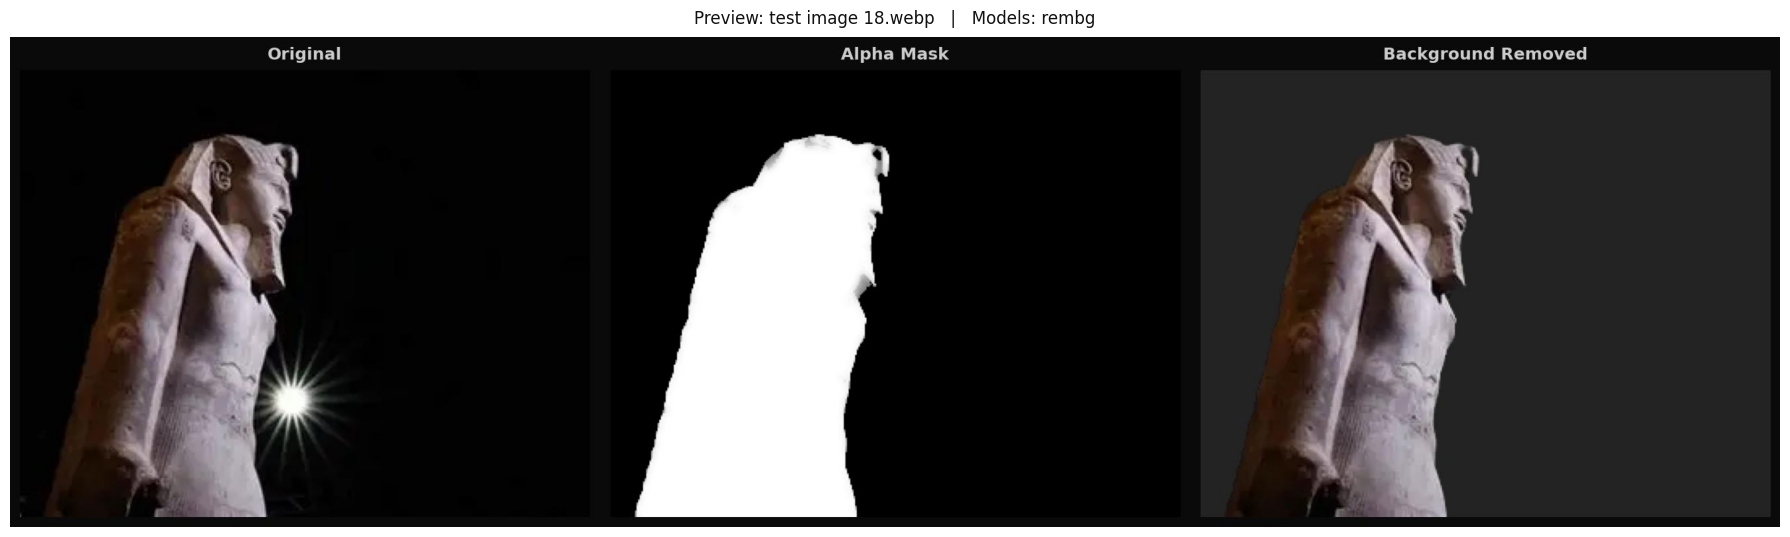

02:18:07  [INFO]  Transparent result saved at: C:\Ahmed Nasser\Artificial Intelligence\Graduation Project\CNN\Remove Background\Model 1\results\test image 18_nobg.png


In [10]:
successful = [r for r in results if r.get("success")]
log.info("%d / %d images processed successfully.", len(successful), len(results))

if successful:
    sample  = successful[0]
    cmp_img = Image.open(sample["comparison"])

    fig, ax = plt.subplots(figsize=(18, 6))
    ax.imshow(cmp_img)
    ax.axis("off")
    ax.set_title(
        f"Preview: {sample['path'].name}   |   Models: {', '.join(sample['models_used'])}",
        fontsize=12, color="#111111", pad=10,
    )
    plt.tight_layout()
    plt.show()

    log.info("Transparent result saved at: %s", sample["result"])
else:
    log.warning("No images were processed successfully. Review the log messages above.")

## Cell 11 — Report Dashboard

Reads the saved JSON report and renders a summary statistics table  
plus a bar chart of processing time per image.

Pipeline              : Background Removal Pipeline — Model 1
Version               : 5.1
Timestamp             : 2026-06-11T02:18:07.300231
GPU Device            : CUDA
BiRefNet Device       : CPU
Output Directory      : C:\Ahmed Nasser\Artificial Intelligence\Graduation Project\CNN\Remove Background\Model 1

Total Images          : 0
Successful            : 91
Failed                : 2
Success Rate          : 9100.0%
Avg Time / Image      : 1.97s
Total Time            : 179.5s
Avg Models Used       : 1.0


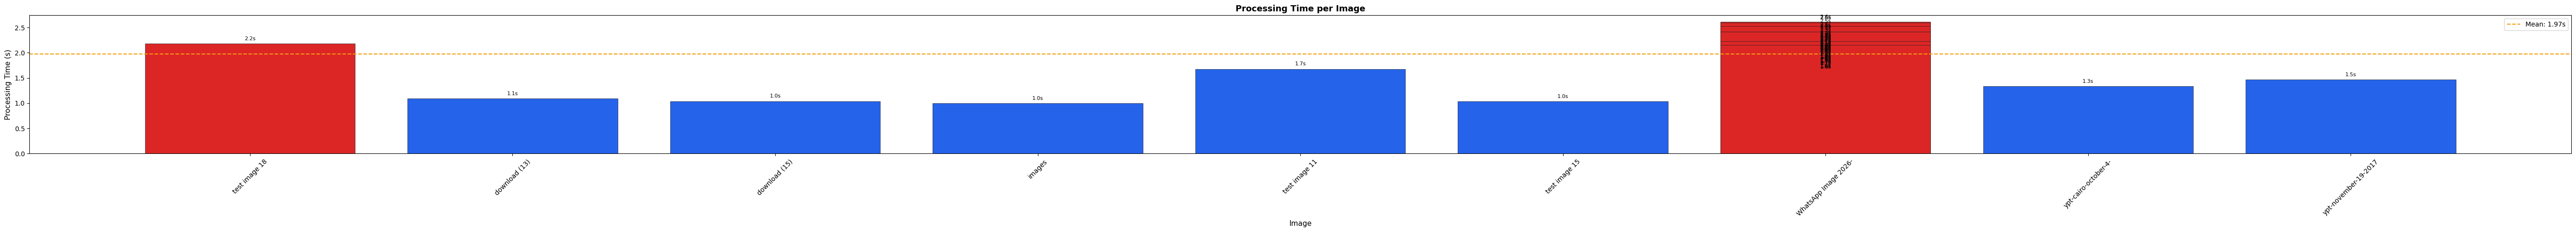

In [11]:
report_path = Path(CONFIG.OUTPUT_DIR) / "processing_report.json"

if not report_path.exists():
    log.warning("Report not found. Run Cell 9 first.")
else:
    with open(report_path, "r", encoding="utf-8") as f:
        report = json.load(f)

    s = report["statistics"]

    print(f"{'Pipeline':<22}: {report['pipeline']}")
    print(f"{'Version':<22}: {report['version']}")
    print(f"{'Timestamp':<22}: {report['timestamp']}")
    print(f"{'GPU Device':<22}: {report['device'].upper()}")
    print(f"{'BiRefNet Device':<22}: {report.get('birefnet_device', 'cpu').upper()}")
    print(f"{'Output Directory':<22}: {report['output_dir']}")
    print()
    print(f"{'Total Images':<22}: {s['total']}")
    print(f"{'Successful':<22}: {s['successful']}")
    print(f"{'Failed':<22}: {s['failed']}")
    print(f"{'Success Rate':<22}: {s['success_rate']}")
    print(f"{'Avg Time / Image':<22}: {s['avg_time_per_image']}")
    print(f"{'Total Time':<22}: {s['total_time']}")
    print(f"{'Avg Models Used':<22}: {s['avg_models_used']}")

    # Bar chart: processing time per image
    image_results = [r for r in report["results"] if r["success"]]
    if image_results:
        names  = [Path(r["input"]).stem[:20] for r in image_results]
        times  = [r["time_seconds"] for r in image_results]
        mean_t = np.mean(times)
        colors = ["#2563eb" if t < mean_t else "#dc2626" for t in times]

        fig, ax = plt.subplots(figsize=(max(10, len(names) * 0.6), 5))
        bars = ax.bar(names, times, color=colors, edgecolor="#1e1e1e", linewidth=0.5)
        ax.axhline(mean_t, color="#f59e0b", linewidth=1.5,
                   linestyle="--", label=f"Mean: {mean_t:.2f}s")
        ax.set_xlabel("Image", fontsize=11)
        ax.set_ylabel("Processing Time (s)", fontsize=11)
        ax.set_title("Processing Time per Image", fontsize=13, fontweight="bold")
        ax.tick_params(axis="x", rotation=45)
        ax.legend()

        for bar, t in zip(bars, times):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.05,
                f"{t:.1f}s",
                ha="center", va="bottom", fontsize=8,
            )

        plt.tight_layout()
        plt.show()